In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
X=np.array([1,2,3,4,5]).reshape(-1,1)
print(X)

[[1]
 [2]
 [3]
 [4]
 [5]]


In [3]:
y=np.array([40,50,50,60,70])
y

array([40, 50, 50, 60, 70])

In [4]:
model=LinearRegression()
model.fit(X,y)

LinearRegression()

In [5]:
print("Intercept:",model.intercept_)
print("SLOPE:",model.coef_[0])

Intercept: 33.0
SLOPE: 7.0


In [6]:
new_data= np.array([[6]])
predicted_mark= model.predict(new_data)
print("predicted marks:",predicted_mark[0])

predicted marks: 75.0


In [7]:
y_pred = model.predict(X)
y_pred

array([40., 47., 54., 61., 68.])

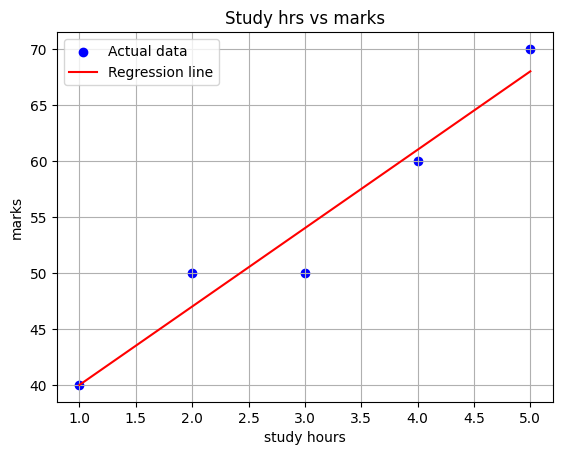

In [8]:
plt.scatter(X,y,color="blue",label="Actual data")
plt.plot(X,y_pred,color="red",label="Regression line")
plt.xlabel("study hours")
plt.ylabel("marks")
plt.title("Study hrs vs marks")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
import numpy as np
from sklearn.metrics import(mean_absolute_error,mean_squared_error,r2_score)
mae=mean_absolute_error(y,y_pred)
mse=mean_squared_error(y,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y,y_pred)
print("MAE:",mae)
print("MSE",mse)
print("RMSE:",rmse)
print("r-squared:",r2)

MAE: 2.0
MSE 6.0
RMSE: 2.449489742783178
r-squared: 0.9423076923076923


In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
data={"Study_hours":[1,2,3,4,5,6,7,8,9,10],
      "marks":[32,38,43,50,54,61,68,73,81,88]}

In [11]:
df=pd.DataFrame(data)
df

,Study_hours,marks
0,1,32
1,2,38
2,3,43
3,4,50
4,5,54
5,6,61
6,7,68
7,8,73
8,9,81
9,10,88


In [12]:
X=df[["Study_hours"]]
y= df["marks"]

In [13]:
X

,Study_hours
0,1
1,2
2,3
3,4
4,5
5,6
6,7
7,8
8,9
9,10


In [14]:
y

0    32
1    38
2    43
3    50
4    54
5    61
6    68
7    73
8    81
9    88
Name: marks, dtype: int64

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [16]:
model=LinearRegression()
model.fit(X_train,y_train)


LinearRegression()

In [17]:
y_pred=model.predict(X_test)

In [18]:
print("Intercept:",model.intercept_)
print("SLOPE:",model.coef_[0])

Intercept: 24.724137931034484
SLOPE: 6.163793103448276


In [43]:
print("actual values:",y_test.values)
print("predicted values:",y_pred)

actual values: [50]
predicted values: [27.78688525 51.20491803 44.21311475 71.73770492 84.05737705]


In [20]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print("MAE:",mae)
print("MSE",mse)
print("RMSE:",rmse)
print("r-squared:",r2)

MAE: 0.875
MSE 0.7709943519619504
RMSE: 0.8780628405541089
r-squared: 0.9983320836085193


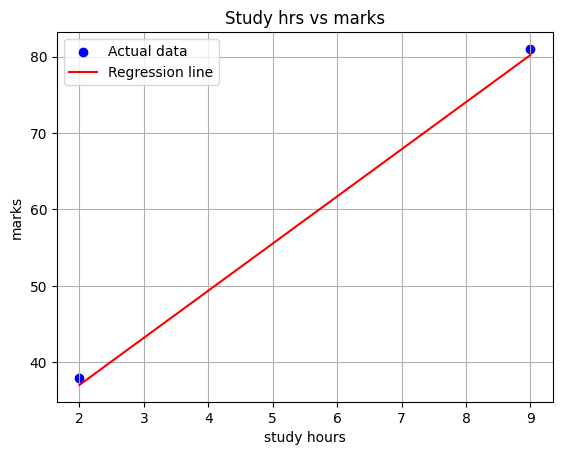

In [21]:
plt.scatter(X_test,y_test,color="blue",label="Actual data")
plt.plot(X_test,y_pred,color="red",label="Regression line")
plt.xlabel("study hours")
plt.ylabel("marks")
plt.title("Study hrs vs marks")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
df = pd.read_csv("../data/student_data.csv")

In [23]:

X=df[["study_hrs","attendance","assignment_score"]]
y=df["final_marks"]
     

In [24]:
model=LinearRegression()
model.fit(X,y)
print("Intercept:",model.intercept_)

Intercept: -28.316528066528065


In [25]:
coeff_table=pd.DataFrame({"feature":X.columns,"coeff":model.coef_})
print(coeff_table)

            feature     coeff
0         study_hrs  0.131410
1        attendance  0.657051
2  assignment_score  0.608108


In [26]:
new_student=pd.DataFrame({"study_hrs":[6],"attendance":[82],"assignment_score":[72]})

In [27]:
prediction=model.predict(new_student)
print("predicted marks:",prediction[0])

predicted marks: 70.13392238392238


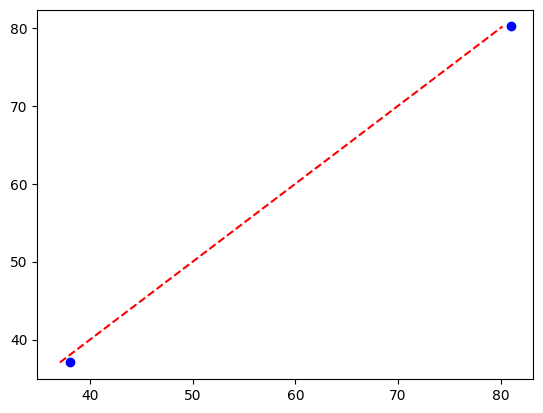

In [28]:
plt.scatter(y_test,y_pred,color="blue")
minimum=min(y_test.min(),y_pred.min())
maximum=min(y_test.max(),y_pred.max())
plt.plot([minimum,maximum],[minimum,maximum],color="red",linestyle="--")

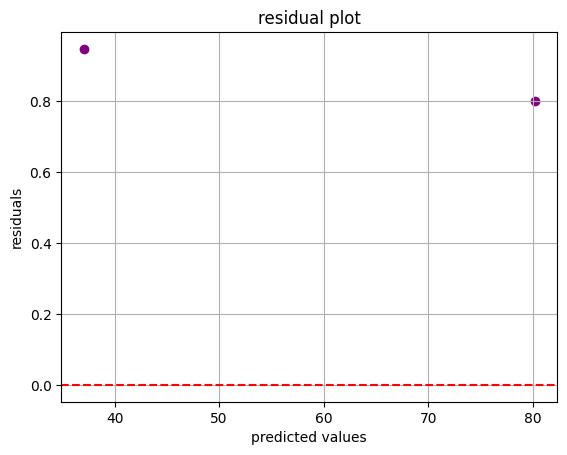

In [29]:
residuals=y_test-y_pred
plt.scatter(y_pred,residuals,color="purple")
plt.axhline(y=0,color="red",linestyle="--")
plt.xlabel("predicted values")
plt.ylabel("residuals")
plt.title("residual plot")
plt.grid(True)
plt.show()

In [30]:
import pandas as pd
data={"Size":[800,1000,1200,1500,1800],
      "Location":["Rural","Urban","Rural","Urban","Urban"],
      "Price":[30,50,42,72,85]
      }
df=pd.DataFrame(data)
df_encoded=pd.get_dummies(df,columns=["Location"],drop_first=True,dtype=int)
print(df_encoded)

   Size  Price  Location_Urban
0   800     30               0
1  1000     50               1
2  1200     42               0
3  1500     72               1
4  1800     85               1


In [31]:
#multiple linear regression
X=df_encoded[["Size","Location_Urban"]]
y=df_encoded["Price"]

In [32]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [33]:
model=LinearRegression()
model.fit(X,y)

LinearRegression()

In [34]:
coeff_table=pd.DataFrame({"feature":X.columns,"coeff":model.coef_})
print(coeff_table)

          feature      coeff
0            Size   0.041066
1  Location_Urban  15.204918


In [35]:
new=pd.DataFrame({"Size":[2000],"Location_Urban":[0]})
prediction=model.predict(new)
print("predicted price:",prediction[0])
y_pred = model.predict(X)
y_pred
import numpy as np
from sklearn.metrics import(mean_absolute_error,mean_squared_error,r2_score)
mae=mean_absolute_error(y,y_pred)
mse=mean_squared_error(y,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y,y_pred)

print("MAE:",mae)
print("MSE",mse)
print("RMSE:",rmse)
print("r-squared:",r2)

predicted price: 77.06557377049178
MAE: 1.367213114754101
MSE 2.4409836065573747
RMSE: 1.562364748244588
r-squared: 0.9939121518192404


In [36]:
'''from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
model=make_pipeline(StandardScaler(),Ridge(alpha=1.0))
model.fit(X_train,y_train)
Y_pred=model.predict(X_test)'''

'from sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.linear_model import Ridge\nmodel=make_pipeline(StandardScaler(),Ridge(alpha=1.0))\nmodel.fit(X_train,y_train)\nY_pred=model.predict(X_test)'

In [37]:
'''for alpha in [0.01,0.1,1,10,100]
model=Ridge(alpha=alpha)
model.fit(X_train,y_train)'''


'for alpha in [0.01,0.1,1,10,100]\nmodel=Ridge(alpha=alpha)\nmodel.fit(X_train,y_train)'

In [38]:
'''from sklearn.linear_model import RidgeCV
model=RidgeCV(alphas=[0.01,0.1,1,10,100],cv=5)
model.fit(X_train,y_train)
print("Best alpha:",model.alpha_)'''

'from sklearn.linear_model import RidgeCV\nmodel=RidgeCV(alphas=[0.01,0.1,1,10,100],cv=5)\nmodel.fit(X_train,y_train)\nprint("Best alpha:",model.alpha_)'

In [39]:
'''from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
model=make_pipeline(StandardScaler(),RidgeCV(alphas=[0.01,0.1,1,10,100]))
model.fit(X_train,y_train)
ridge_model=model.named_steps["ridgecv"]
print("Best alpha:",ridge_model.alpha_)'''

'from sklearn.pipeline import make_pipeline\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.linear_model import RidgeCV\nmodel=make_pipeline(StandardScaler(),RidgeCV(alphas=[0.01,0.1,1,10,100]))\nmodel.fit(X_train,y_train)\nridge_model=model.named_steps["ridgecv"]\nprint("Best alpha:",ridge_model.alpha_)'